<a href="https://colab.research.google.com/github/keyvanmahmoudi/Machine_Learning_Course/blob/main/sessions/Session09_ensemble_methods.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# جلسهٔ ۹: روش‌های گروهی (Ensemble Learning)

### اهداف این جلسه

- درک ایدهٔ «خرد جمعی» و رأی‌گیری بین مدل‌ها
- **Bagging** و **Random Forest**: کاهش واریانس با ترکیب درخت‌های مستقل
- **Boosting**: کاهش بایاس با ساختن درخت‌های پشت سر هم
- پیاده‌سازی سادهٔ **Gradient Boosting** از صفر
- آشنایی با کتابخانه‌های صنعتی: HistGradientBoosting، **XGBoost** و **LightGBM**
- روش قابل اعتماد سنجش اهمیت ویژگی: **Permutation Importance**

برای داده‌های جدولی (جدول‌هایی مثل اکسل)، مدل‌های گروهی مبتنی بر درخت، به‌خصوص Gradient Boosting، امروز معمولاً **قوی‌ترین** انتخاب هستند؛ حتی قوی‌تر از شبکه‌های عصبی.

## ۱. خرد جمعی

اگر از ۱۰۰۰ نفر بخواهید وزن یک گاو را حدس بزنند، میانگین حدس‌ها معمولاً از حدس تک‌تک افراد، حتی کارشناسان، دقیق‌تر است. شرط اصلی: خطاهای افراد **مستقل** و متنوع باشند تا همدیگر را خنثی کنند.

همین ایده برای مدل‌ها هم صادق است. ابتدا چند مدل **متفاوت** را با رأی‌گیری ترکیب می‌کنیم:

- **رأی سخت (Hard Voting):** کلاسی که بیشترین رأی را دارد.
- **رأی نرم (Soft Voting):** میانگین احتمال‌ها؛ معمولاً بهتر است چون اطمینان هر مدل را هم در نظر می‌گیرد.

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import seaborn as sns

sns.set_theme(style="whitegrid")

X, y = make_moons(n_samples=600, noise=0.3, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

members = [
    ("logistic", LogisticRegression()),
    ("svm", make_pipeline(StandardScaler(), CalibratedClassifierCV(SVC(), ensemble=False))),
    ("tree", DecisionTreeClassifier(max_depth=5, random_state=42)),
    ("knn", KNeighborsClassifier(n_neighbors=15)),
]
for name, model in members:
    print(f"{name:<10} test accuracy = {model.fit(X_train, y_train).score(X_test, y_test):.3f}")

for voting in ["hard", "soft"]:
    ensemble = VotingClassifier(members, voting=voting).fit(X_train, y_train)
    print(f"{voting + ' vote':<10} test accuracy = {ensemble.score(X_test, y_test):.3f}")

logistic   test accuracy = 0.844
svm        test accuracy = 0.889
tree       test accuracy = 0.894
knn        test accuracy = 0.894
hard vote  test accuracy = 0.894
soft vote  test accuracy = 0.900


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

گروه مدل‌ها معمولاً دست‌کم به خوبی بهترین عضو است و اغلب از آن بهتر. ولی مدل‌های متفاوت ساختن و تنظیم کردن زحمت دارد. دو خانوادهٔ اصلی روش‌های گروهی، این کار را به‌صورت سیستماتیک با **تعداد زیادی درخت تصمیم** انجام می‌دهند.

## ۲. Bagging: میانگین‌گیری از مدل‌های مستقل

در جلسهٔ قبل دیدیم درخت‌ها **واریانس زیاد** دارند. ایدهٔ **Bagging** (مخفف Bootstrap Aggregating):

1. از دادهٔ آموزش، $B$ نمونهٔ **بوت‌استرپ** بساز؛ یعنی هر بار $m$ نمونه را **با جایگذاری** انتخاب کن. هر نمونهٔ بوت‌استرپ حدود ۶۳٪ از داده‌های یکتا را دارد.
2. روی هر نمونه یک درخت عمیق (کم‌بایاس و پرواریانس) آموزش بده.
3. پیش‌بینی‌ها را ترکیب کن: رأی اکثریت برای طبقه‌بندی و میانگین برای رگرسیون.

میانگین‌گیری از مدل‌هایی که خطاهای تا حدی مستقل دارند، **واریانس را کم می‌کند** و بایاس را تقریباً ثابت نگه می‌دارد.

</div>

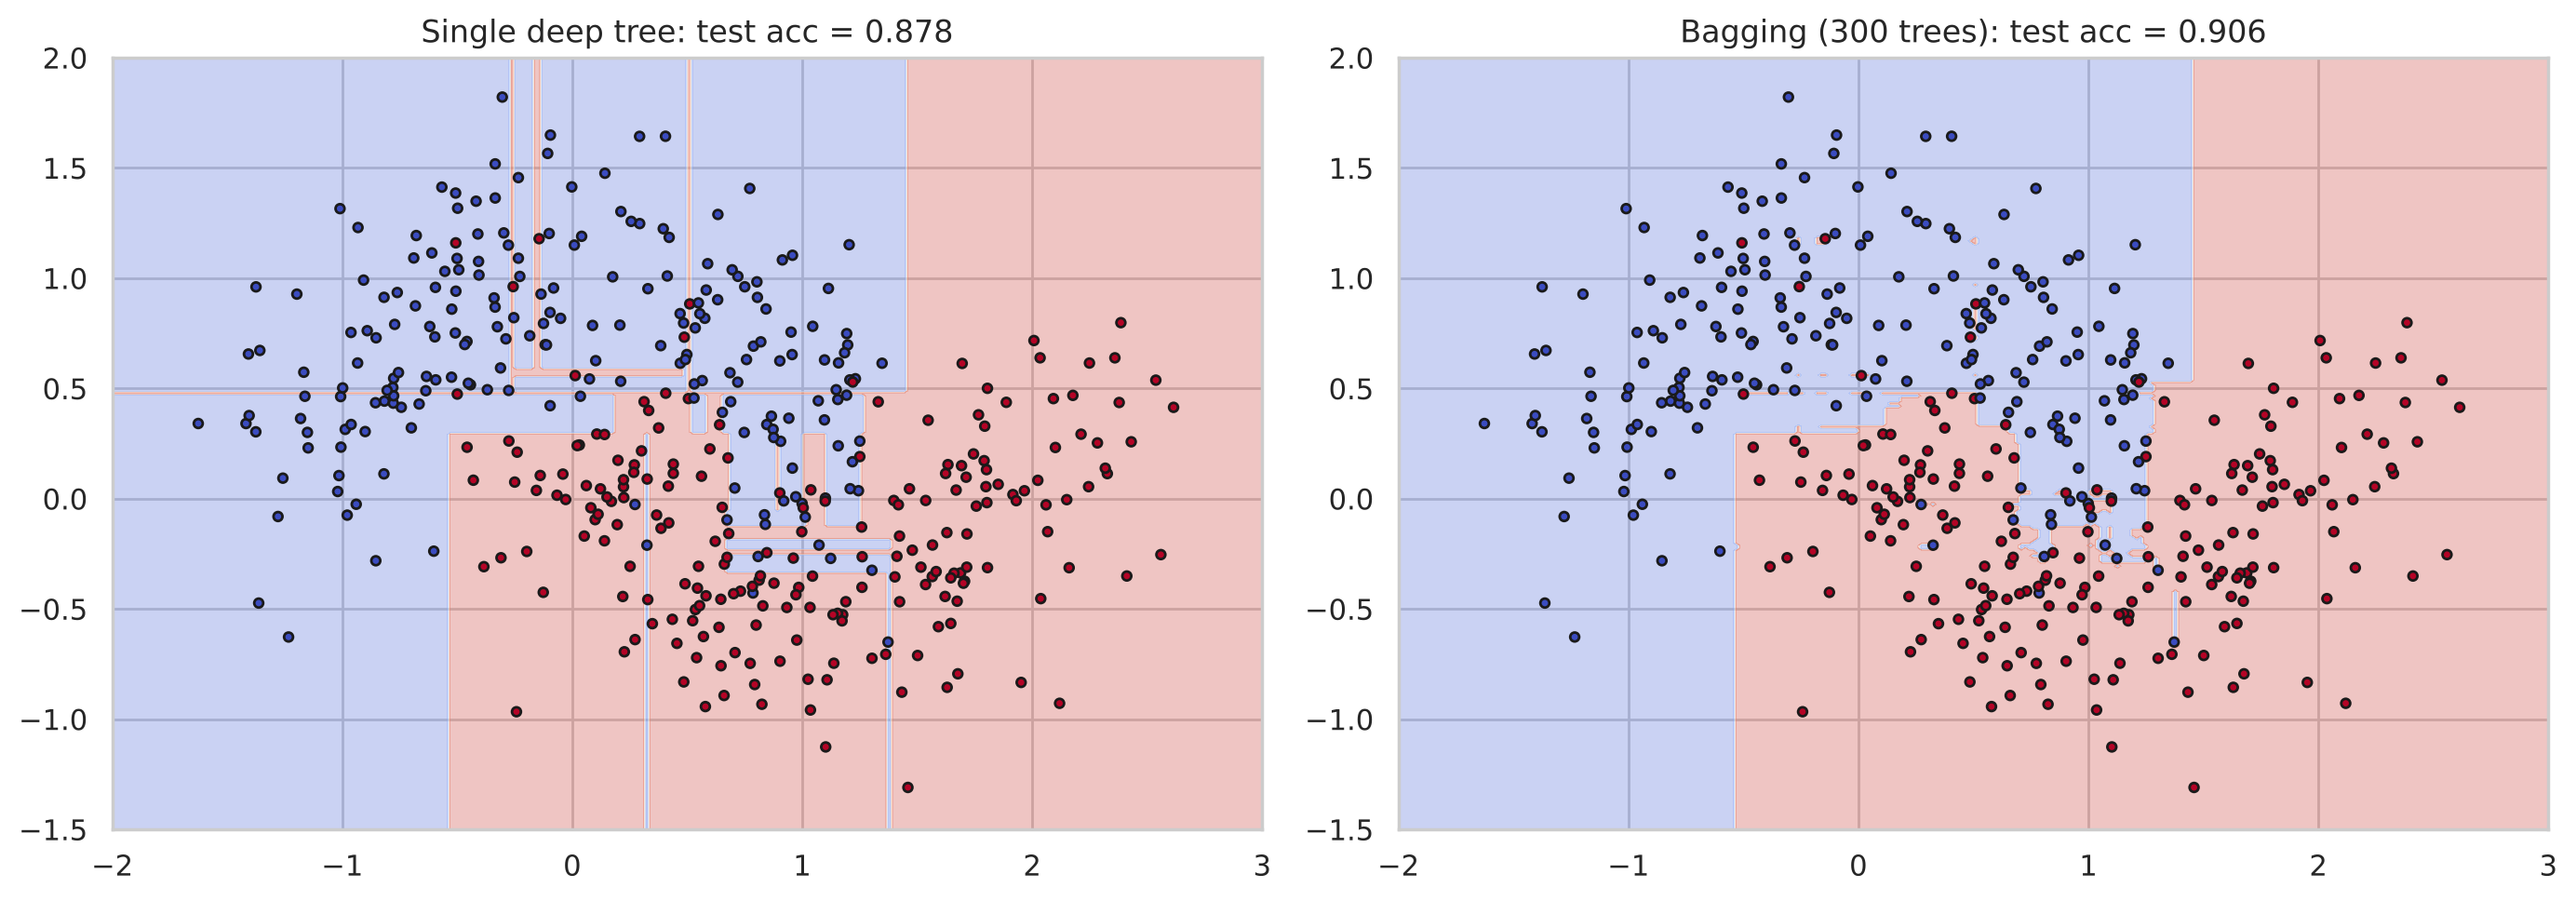

In [2]:
from sklearn.ensemble import BaggingClassifier

def plot_boundary(model, X, y, ax, title):
    xx, yy = np.meshgrid(np.linspace(-2, 3, 300), np.linspace(-1.5, 2, 300))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=12)
    ax.set_title(title)

single_tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
bagging = BaggingClassifier(DecisionTreeClassifier(), n_estimators=300, oob_score=True,
                            random_state=42, n_jobs=-1).fit(X_train, y_train)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_boundary(single_tree, X_train, y_train, axes[0], f"Single deep tree: test acc = {single_tree.score(X_test, y_test):.3f}")
plot_boundary(bagging, X_train, y_train, axes[1], f"Bagging (300 trees): test acc = {bagging.score(X_test, y_test):.3f}")
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

مرز تصمیم درخت تنها پر از جزیره‌های کوچک و بیش‌برازش است. Bagging همان درخت‌های عمیق را ترکیب کرده و مرزی نرم‌تر با جزیره‌های بسیار کمتر ساخته که روی دادهٔ آزمون بهتر عمل می‌کند.

### ارزیابی Out-of-Bag (OOB)

هر درخت حدود ۳۷٪ از داده‌ها را هرگز نمی‌بیند. می‌توانیم هر نمونه را فقط با درخت‌هایی که آن را ندیده‌اند ارزیابی کنیم. این **امتیاز OOB** تخمینی رایگان از دقت روی دادهٔ نادیده است، بدون نیاز به دادهٔ اعتبارسنجی جداگانه:

</div>

In [3]:
print(f"OOB accuracy estimate: {bagging.oob_score_:.3f}")
print(f"Actual test accuracy:  {bagging.score(X_test, y_test):.3f}")

OOB accuracy estimate: 0.907
Actual test accuracy:  0.906


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۳. جنگل تصادفی (Random Forest)

اگر یک ویژگی خیلی قوی وجود داشته باشد، تقریباً همهٔ درخت‌های Bagging با همان ویژگی شروع می‌کنند و درخت‌ها **شبیه هم** می‌شوند؛ خطاهایشان همبسته است و میانگین‌گیری کمتر کمک می‌کند.

**Random Forest** یک تصادفی‌سازی دیگر اضافه می‌کند: در **هر گره**، فقط زیرمجموعه‌ای تصادفی از ویژگی‌ها (`max_features`) برای تقسیم بررسی می‌شود. این کار درخت‌ها را متنوع‌تر و همبستگی بینشان را کمتر می‌کند. نتیجه معمولاً مدلی قوی است که **با تنظیمات پیش‌فرض هم خوب کار می‌کند**.

برای مقایسهٔ واقعی، به دادهٔ **قیمت مسکن کالیفرنیا** از جلسهٔ ۳ برمی‌گردیم؛ جایی که رگرسیون خطی به $R^2 \approx 0.64$ رسید.

</div>

In [4]:
DATA_URL = "https://raw.githubusercontent.com/keyvanmahmoudi/Machine_Learning_Course/main/data/"
housing = pd.read_csv(DATA_URL + "housing.csv")
housing["rooms_per_household"] = housing["total_rooms"] / housing["households"]
housing["bedrooms_ratio"] = housing["total_bedrooms"] / housing["total_rooms"]
housing["people_per_household"] = housing["population"] / housing["households"]

X_h = housing.drop(columns="median_house_value")
y_h = housing["median_house_value"]
Xh_train, Xh_test, yh_train, yh_test = train_test_split(X_h, y_h, test_size=0.2, random_state=42)

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

مدل‌های درختی به مقیاس‌بندی نیاز ندارند. برای ویژگی دسته‌ای `ocean_proximity` از `OrdinalEncoder` استفاده می‌کنیم؛ برای درخت‌ها این روش ساده و کافی است، چون درخت می‌تواند با چند تقسیم، دسته‌ها را از هم جدا کند. مقادیر گمشده را هم با میانه پر می‌کنیم.

</div>

In [5]:
import time
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error, r2_score

numeric = X_h.select_dtypes("number").columns.tolist()
tree_preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric),
    ("cat", OrdinalEncoder(), ["ocean_proximity"]),
], verbose_feature_names_out=False)

results = []
def evaluate(name, model):
    start = time.perf_counter()
    model.fit(Xh_train, yh_train)
    elapsed = time.perf_counter() - start
    pred = model.predict(Xh_test)
    results.append({"model": name, "RMSE": root_mean_squared_error(yh_test, pred),
                    "R2": r2_score(yh_test, pred), "train time (s)": elapsed})
    return model

linear_preprocessor = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["ocean_proximity"]),
])
evaluate("Linear regression", Pipeline([("prep", linear_preprocessor), ("model", LinearRegression())]))
evaluate("Single decision tree", Pipeline([("prep", tree_preprocessor),
                                           ("model", DecisionTreeRegressor(random_state=42))]))
rf = evaluate("Random forest (100 trees)", Pipeline([("prep", tree_preprocessor),
                                                    ("model", RandomForestRegressor(n_estimators=100, oob_score=True,
                                                                                    n_jobs=-1, random_state=42))]))
pd.DataFrame(results).round(3)

,model,RMSE,R2,train time (s)
0,Linear regression,69127.038,0.635,0.032
1,Single decision tree,71111.491,0.614,0.191
2,Random forest (100 trees),50136.369,0.808,5.882


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

جنگل تصادفی بدون هیچ تنظیمی، $R^2$ را از حدود ۰٫۶۴ رگرسیون خطی به بیش از ۰٫۸ رسانده است. درخت تنها، به خاطر بیش‌برازش، از جنگل بسیار ضعیف‌تر است.

### تعداد درخت‌ها

افزایش تعداد درخت‌ها در Random Forest **بیش‌برازش ایجاد نمی‌کند**؛ فقط از یک جایی به بعد بهبودی هم نمی‌دهد و محاسبه را کندتر می‌کند:

</div>

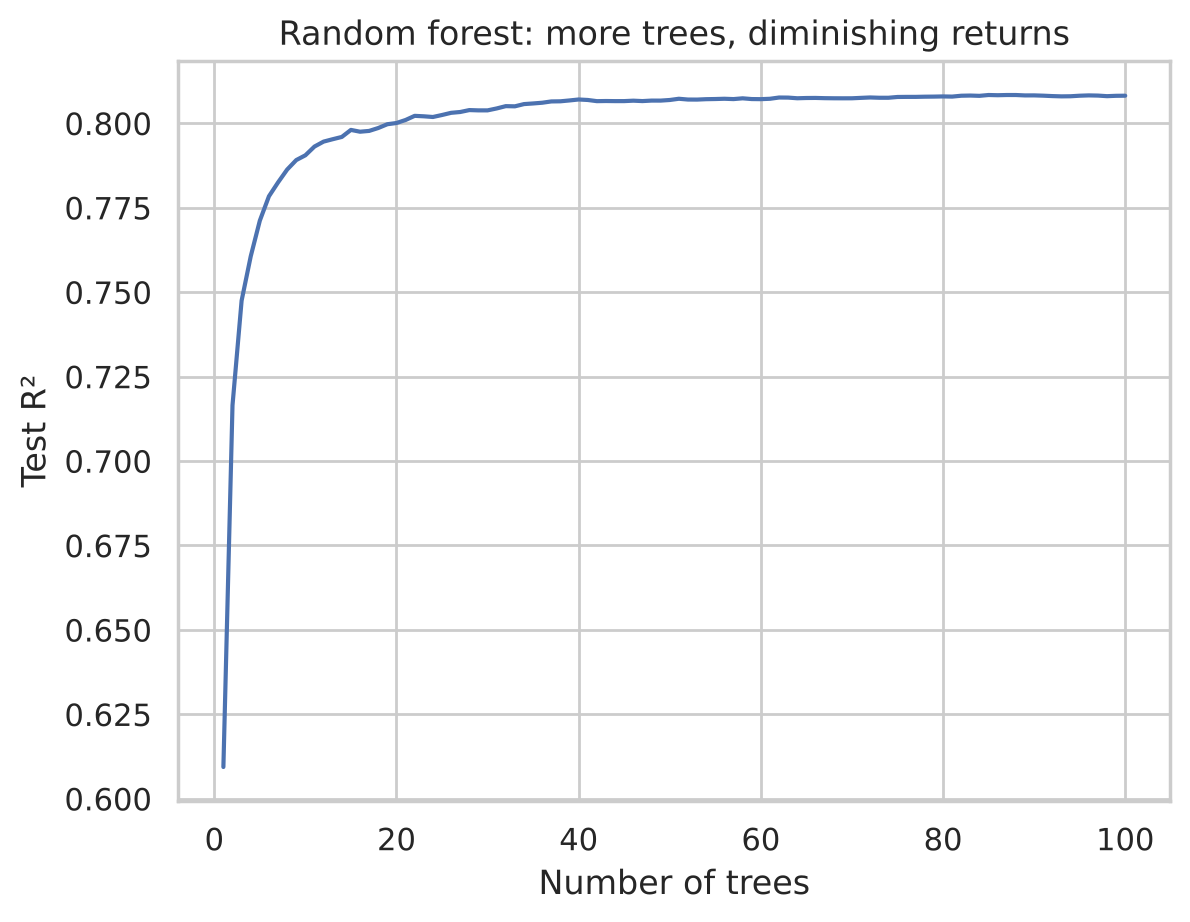

OOB R² estimate: 0.809


In [6]:
forest = rf.named_steps["model"]
X_test_prep = rf.named_steps["prep"].transform(Xh_test)

all_preds = np.stack([t.predict(X_test_prep) for t in forest.estimators_])
cumulative_r2 = [r2_score(yh_test, all_preds[:n].mean(axis=0)) for n in range(1, len(all_preds) + 1)]

plt.plot(range(1, len(all_preds) + 1), cumulative_r2)
plt.xlabel("Number of trees")
plt.ylabel("Test R²")
plt.title("Random forest: more trees, diminishing returns")
plt.show()
print(f"OOB R² estimate: {forest.oob_score_:.3f}")

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۴. اهمیت ویژگی‌ها: Impurity در برابر Permutation

دو روش برای سنجش اهمیت ویژگی‌ها:

- **مبتنی بر ناخالصی (`feature_importances_`):** سریع، ولی روی دادهٔ **آموزش** حساب می‌شود و ویژگی‌های با مقادیر یکتای زیاد را بیش از حد مهم نشان می‌دهد.
- **جایگشتی (Permutation Importance):** مقادیر یک ستون را روی دادهٔ **آزمون** به‌طور تصادفی به هم می‌ریزیم و می‌بینیم عملکرد مدل چقدر افت می‌کند. اگر افت زیاد باشد، مدل به آن ویژگی وابسته است. این روش برای **هر مدلی** قابل استفاده و قابل اعتمادتر است.

</div>

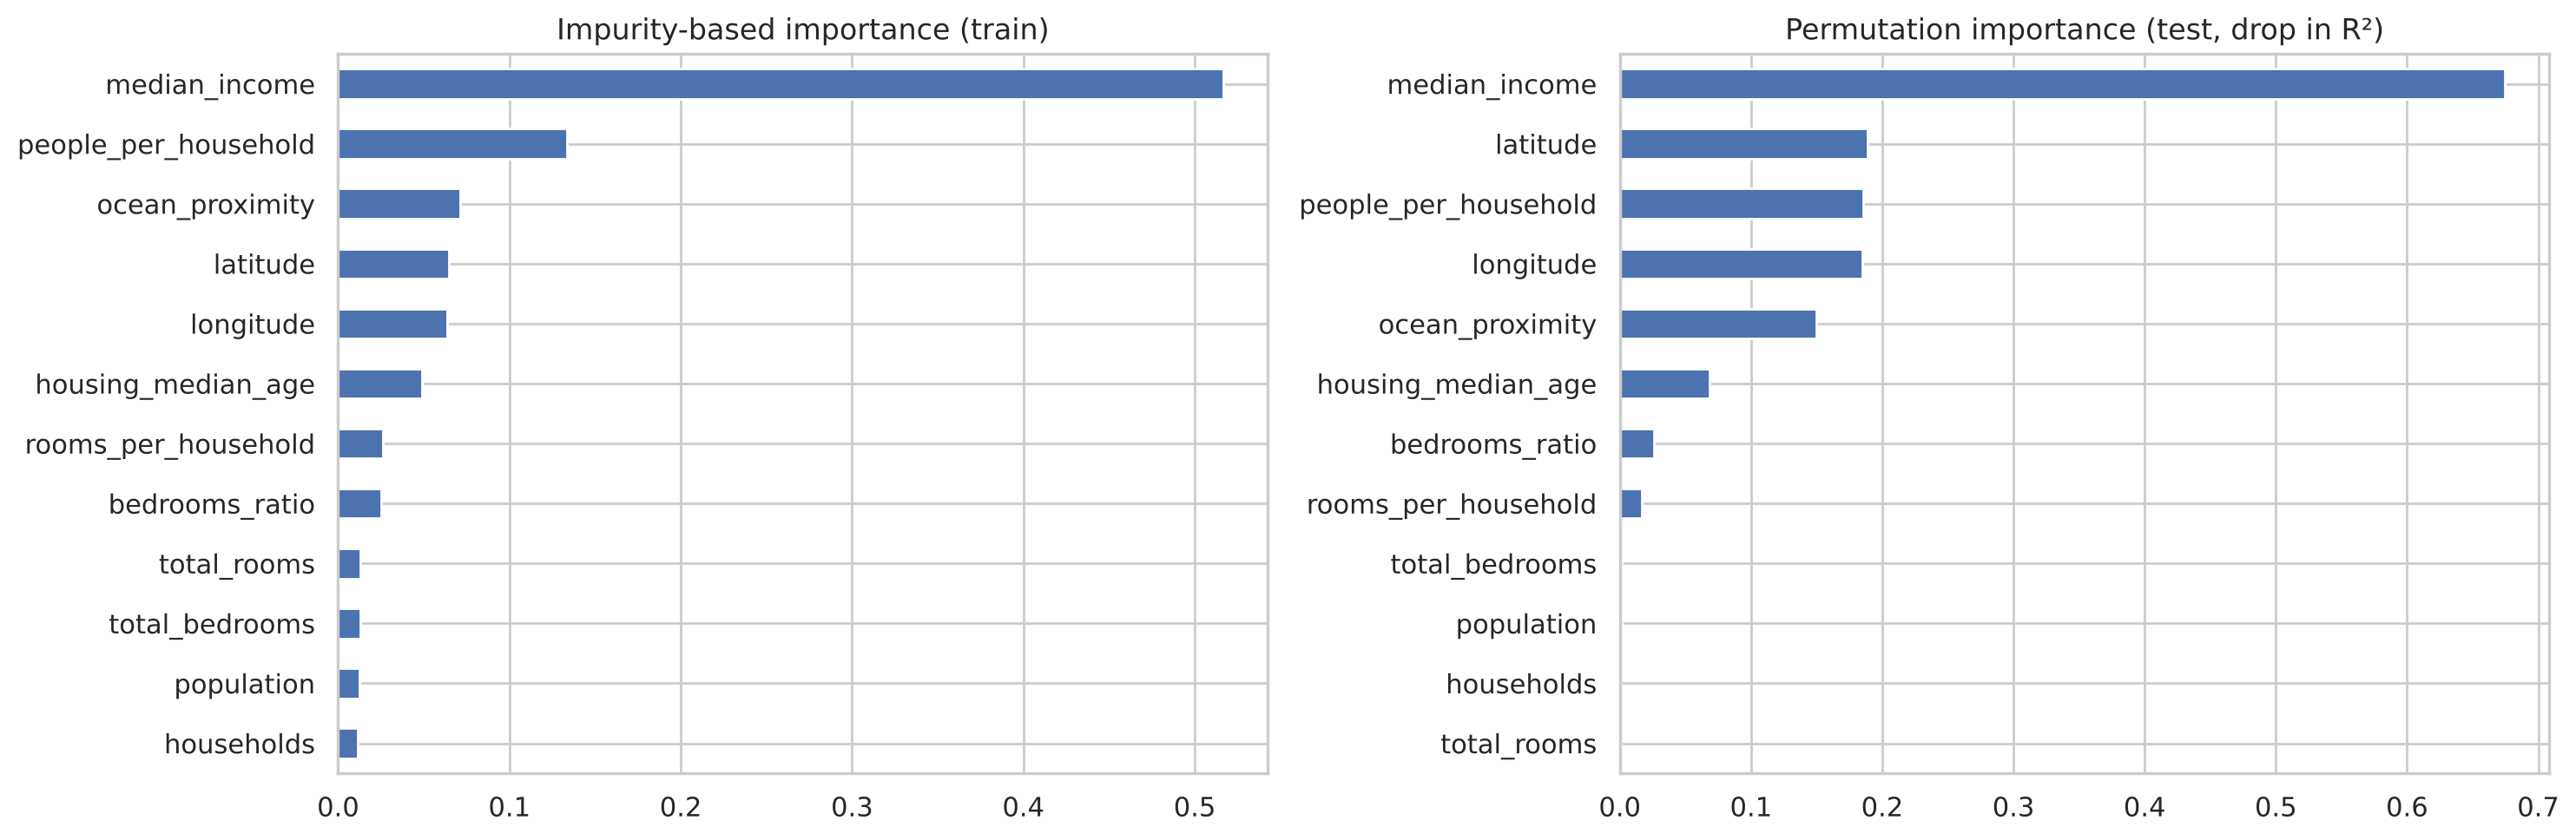

In [7]:
from sklearn.inspection import permutation_importance

feature_names = rf.named_steps["prep"].get_feature_names_out()
impurity_imp = pd.Series(forest.feature_importances_, index=feature_names)
perm = permutation_importance(forest, X_test_prep, yh_test, n_repeats=5, random_state=42, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=feature_names)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
impurity_imp.sort_values().plot.barh(ax=axes[0], title="Impurity-based importance (train)")
perm_imp.sort_values().plot.barh(ax=axes[1], title="Permutation importance (test, drop in R²)")
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

در هر دو روش، `median_income` مهم‌ترین ویژگی است و موقعیت جغرافیایی (`longitude`، `latitude` و `ocean_proximity`) بعد از آن می‌آید. تفاوت‌های ترتیب در ویژگی‌های میانی نشان می‌دهد که نباید فقط به یک روش تکیه کرد.

**هشدار:** اهمیت ویژگی یعنی **مدل** به آن ویژگی وابسته است، نه اینکه آن ویژگی **علت** هدف است.

## ۵. Boosting: یادگیری از اشتباه‌ها

در Bagging درخت‌ها **موازی و مستقل** ساخته می‌شوند. در **Boosting** مدل‌ها **پشت سر هم** ساخته می‌شوند و هر مدل جدید تلاش می‌کند **اشتباه‌های مدل‌های قبلی** را جبران کند. معمولاً از درخت‌های **کم‌عمق** (یادگیرنده‌های ضعیف با بایاس زیاد) استفاده می‌شود و Boosting به‌تدریج **بایاس را کم می‌کند**.

| | Bagging / Random Forest | Boosting |
|---|---|---|
| ساخت مدل‌ها | موازی و مستقل | ترتیبی، هر مدل وابسته به قبلی |
| مدل پایه | درخت عمیق (واریانس زیاد) | درخت کم‌عمق (بایاس زیاد) |
| کاهش | واریانس | بایاس |
| خطر بیش‌برازش با مدل‌های بیشتر | تقریباً نه | بله؛ نیاز به توقف زودهنگام |

### ۵.۱ AdaBoost

**AdaBoost** (Adaptive Boosting) اولین الگوریتم Boosting موفق بود: بعد از هر مدل، وزن نمونه‌هایی که اشتباه طبقه‌بندی شده‌اند را افزایش می‌دهد تا مدل بعدی روی آن‌ها تمرکز کند. پیش‌بینی نهایی، رأی وزن‌دار همهٔ مدل‌هاست.

</div>

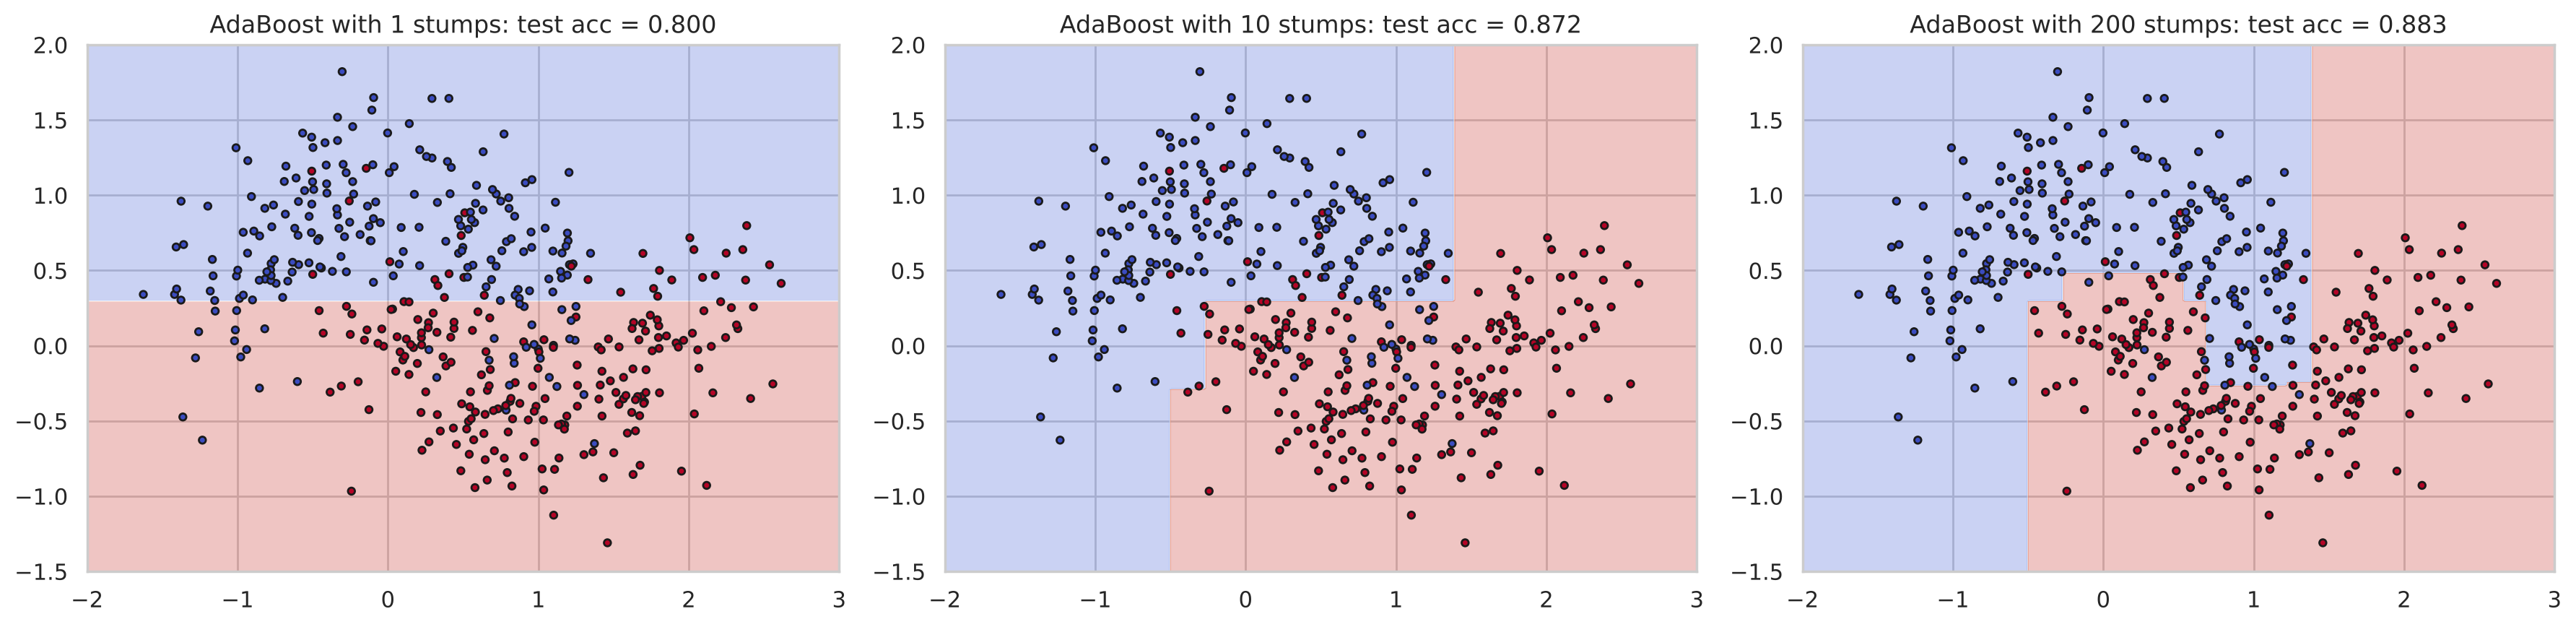

In [8]:
from sklearn.ensemble import AdaBoostClassifier

stump = DecisionTreeClassifier(max_depth=1)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, n in zip(axes, [1, 10, 200]):
    ada = AdaBoostClassifier(stump, n_estimators=n, learning_rate=0.5, random_state=42).fit(X_train, y_train)
    plot_boundary(ada, X_train, y_train, ax, f"AdaBoost with {n} stumps: test acc = {ada.score(X_test, y_test):.3f}")
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

یک «کُندهٔ درخت» (درخت با عمق ۱) فقط یک خط عمودی یا افقی است. ولی ترکیب ۲۰۰ تای آن‌ها یک مرز پیچیده و دقیق می‌سازد.

### ۵.۲ Gradient Boosting

**Gradient Boosting** ایدهٔ کلی‌تری دارد: هر درخت جدید روی **باقیمانده‌ها (خطاهای)** مدل فعلی آموزش می‌بیند. برای MSE، باقیمانده دقیقاً منفیِ گرادیان تابع هزینه است؛ نام «گرادیان» از همین‌جا می‌آید. Gradient Boosting در واقع **گرادیان کاهشی در فضای توابع** است:

$$F_0(x) = \bar{y} \qquad r_i^{(t)} = y_i - F_{t-1}(x_i) \qquad F_t(x) = F_{t-1}(x) + \eta \cdot h_t(x)$$

که $h_t$ درختی است که روی باقیمانده‌های $r^{(t)}$ آموزش دیده و $\eta$ **نرخ یادگیری** است. بیایید این را از صفر پیاده کنیم:

</div>

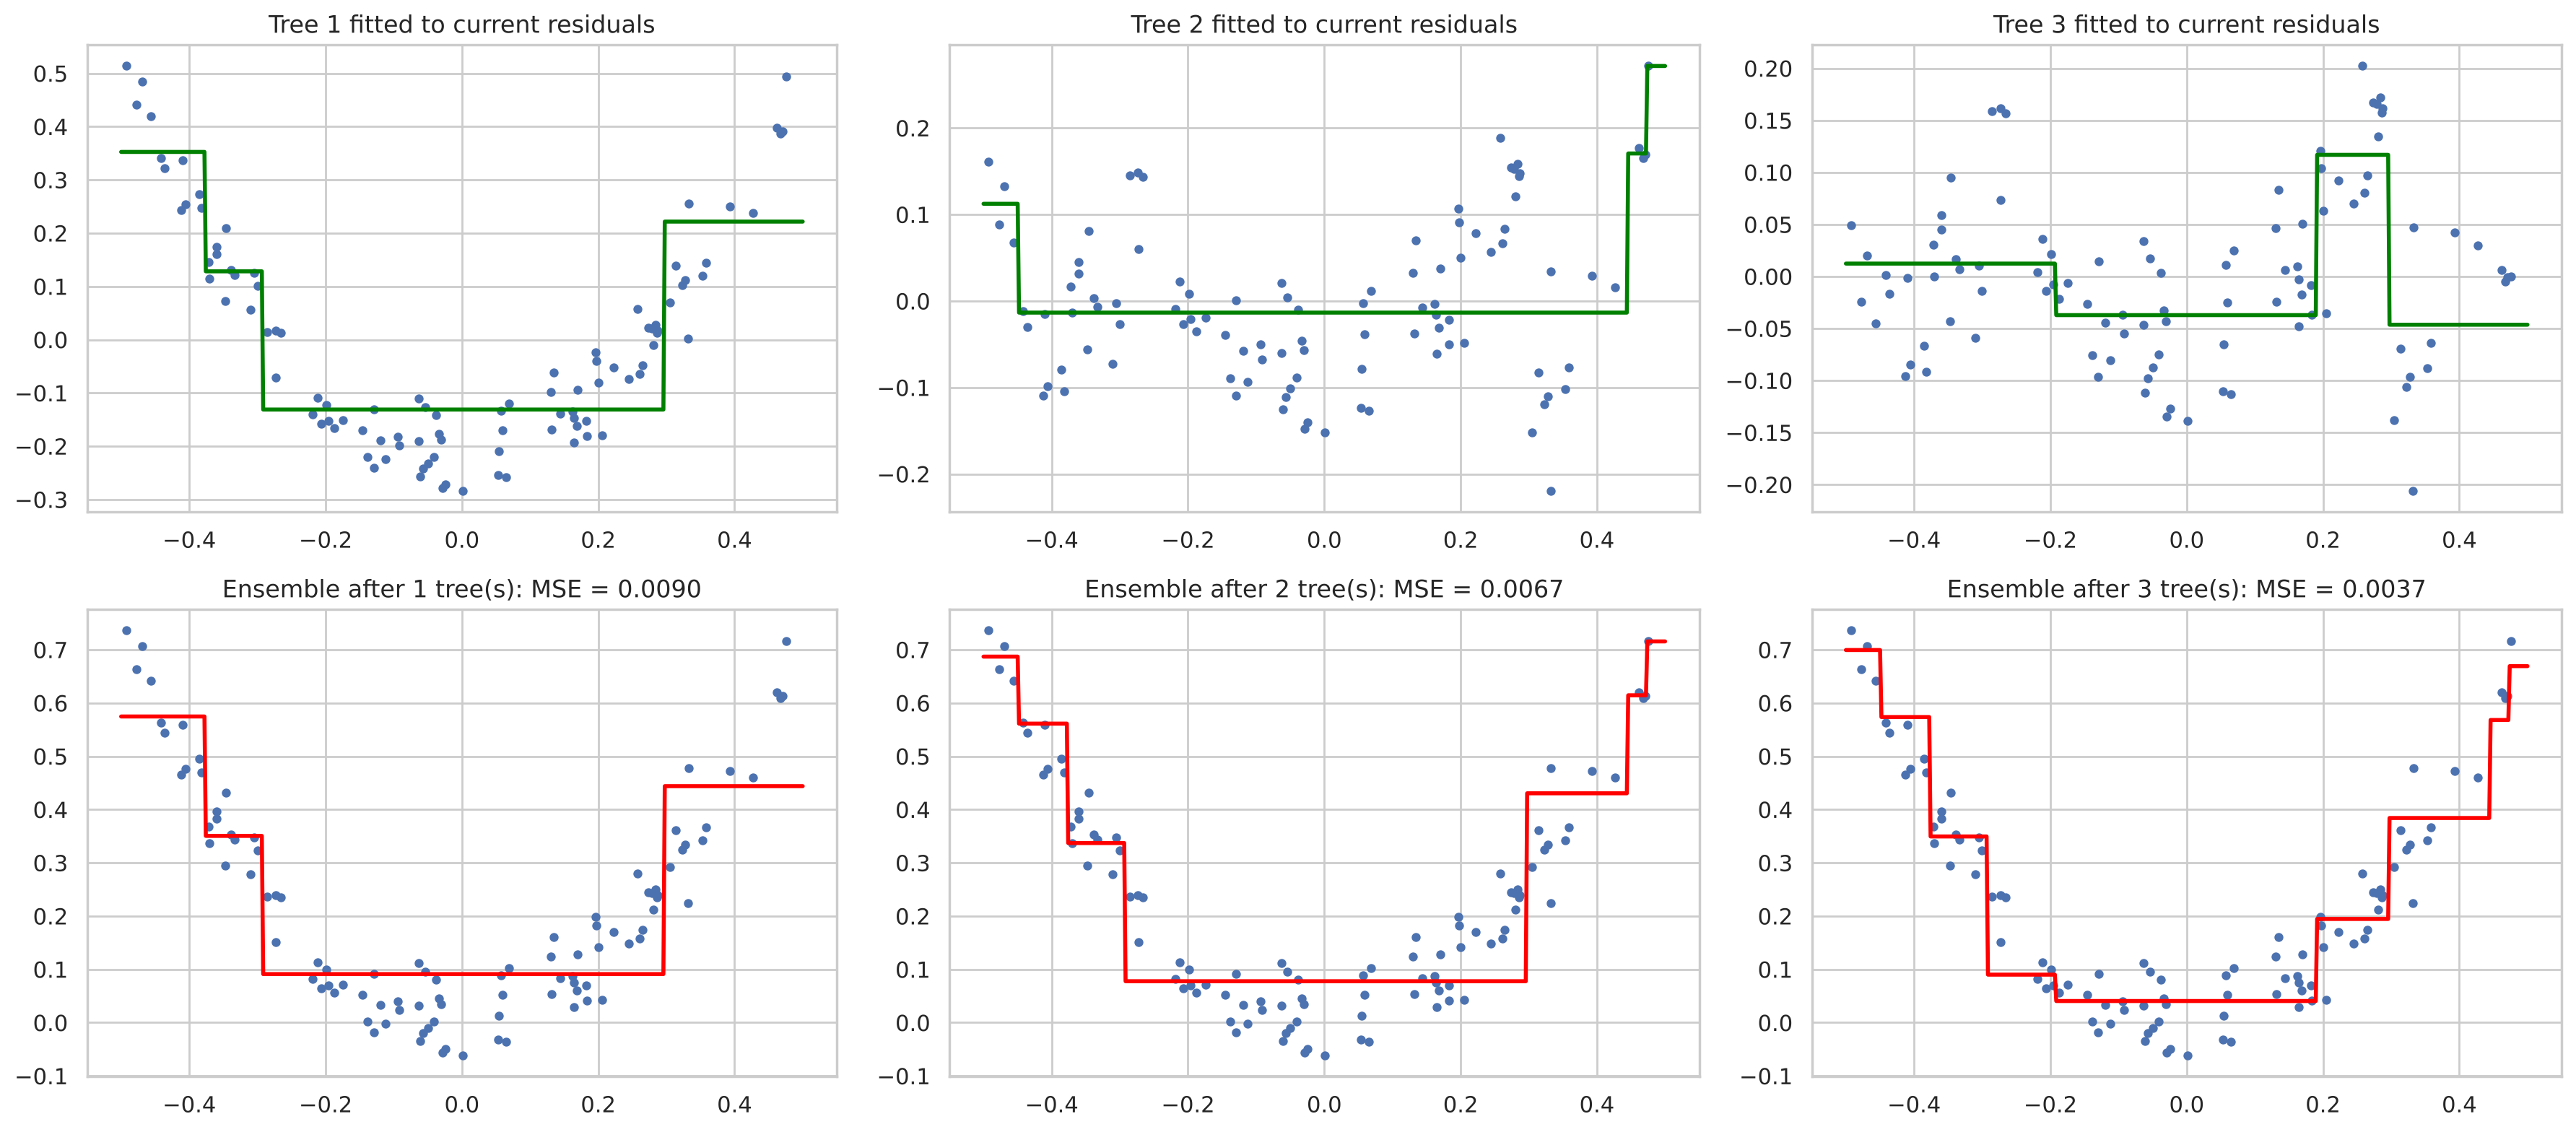

In [9]:
rng = np.random.default_rng(42)
X_s = rng.uniform(-0.5, 0.5, (100, 1))
y_s = 3 * X_s[:, 0] ** 2 + rng.normal(0, 0.05, 100)
x_plot = np.linspace(-0.5, 0.5, 500).reshape(-1, 1)

learning_rate = 1.0
prediction = np.full_like(y_s, y_s.mean())
plot_prediction = np.full(len(x_plot), y_s.mean())

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for t in range(3):
    residuals = y_s - prediction
    tree_t = DecisionTreeRegressor(max_depth=2, random_state=42).fit(X_s, residuals)
    prediction += learning_rate * tree_t.predict(X_s)
    plot_prediction += learning_rate * tree_t.predict(x_plot)

    axes[0, t].scatter(X_s, residuals, s=12)
    axes[0, t].plot(x_plot, tree_t.predict(x_plot), color="green", linewidth=2)
    axes[0, t].set_title(f"Tree {t + 1} fitted to current residuals")
    axes[1, t].scatter(X_s, y_s, s=12)
    axes[1, t].plot(x_plot, plot_prediction, color="red", linewidth=2)
    axes[1, t].set_title(f"Ensemble after {t + 1} tree(s): MSE = {np.mean((y_s - prediction) ** 2):.4f}")
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

- ردیف بالا: هر درخت جدید، خطای باقیماندهٔ مرحلهٔ قبل را مدل می‌کند.
- ردیف پایین: با اضافه شدن هر درخت، پیش‌بینی گروه به داده نزدیک‌تر می‌شود.

**نرخ یادگیری و تعداد درخت‌ها** با هم کار می‌کنند: نرخ یادگیری کوچک‌تر (مثلاً ۰٫۱ یا ۰٫۰۵) معمولاً تعمیم بهتری می‌دهد ولی درخت‌های بیشتری لازم دارد (به این کار **shrinkage** می‌گویند). برخلاف Random Forest، با درخت‌های **بیش از حد** زیاد، Gradient Boosting **بیش‌برازش می‌کند**؛ پس از **توقف زودهنگام (Early Stopping)** استفاده می‌کنیم:

</div>

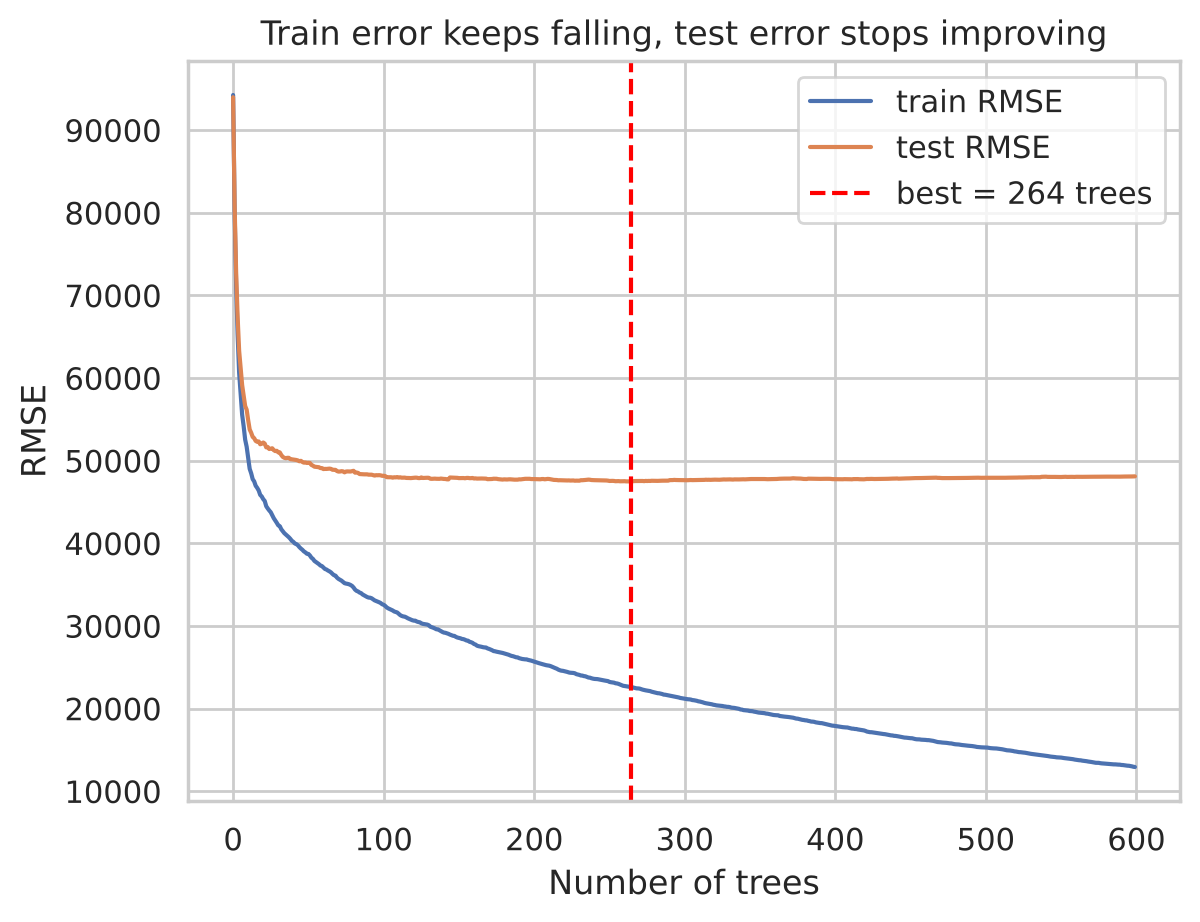

In [10]:
from sklearn.ensemble import GradientBoostingRegressor

X_train_prep = tree_preprocessor.fit_transform(Xh_train)
X_test_prep = tree_preprocessor.transform(Xh_test)

gbr = GradientBoostingRegressor(n_estimators=600, learning_rate=0.3, max_depth=5, random_state=42)
gbr.fit(X_train_prep, yh_train)

train_err = [root_mean_squared_error(yh_train, p) for p in gbr.staged_predict(X_train_prep)]
test_err = [root_mean_squared_error(yh_test, p) for p in gbr.staged_predict(X_test_prep)]

plt.plot(train_err, label="train RMSE")
plt.plot(test_err, label="test RMSE")
best_n = int(np.argmin(test_err)) + 1
plt.axvline(best_n, color="red", linestyle="--", label=f"best = {best_n} trees")
plt.xlabel("Number of trees")
plt.ylabel("RMSE")
plt.title("Train error keeps falling, test error stops improving")
plt.legend()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

خطای آموزش مدام کم می‌شود، ولی خطای آزمون بعد از حدود دویست و چند درخت دیگر بهتر نمی‌شود و کمی هم بالا می‌رود. فاصلهٔ روزافزون بین دو منحنی یعنی درخت‌های اضافه فقط دادهٔ آموزش را حفظ می‌کنند و فقط هزینهٔ محاسبه اضافه می‌کنند. (اینجا برای نمایش از دادهٔ آزمون استفاده کردیم؛ در عمل، تعداد بهینه را با دادهٔ **اعتبارسنجی** پیدا می‌کنیم. پارامترهای `n_iter_no_change` و `validation_fraction` این کار را خودکار انجام می‌دهند.)

## ۶. کتابخانه‌های صنعتی Gradient Boosting

پیاده‌سازی کلاسیک `GradientBoostingRegressor` برای دادهٔ بزرگ کند است. سه پیاده‌سازی مدرن که در صنعت و مسابقات Kaggle استفاده می‌شوند:

- **HistGradientBoosting** (در خود scikit-learn): ویژگی‌ها را در ۲۵۵ «سطل» گسسته می‌کند و بسیار سریع است. مقادیر گمشده و ویژگی‌های دسته‌ای را هم مستقیم پشتیبانی می‌کند.
- **XGBoost:** منظم‌سازی قوی‌تر و بهینه‌سازی‌های فراوان؛ سال‌ها برندهٔ مسابقات دادهٔ جدولی.
- **LightGBM** (از مایکروسافت): رشد درخت به‌صورت برگ‌محور؛ بسیار سریع روی دادهٔ بزرگ.

همهٔ این‌ها رابط سازگار با scikit-learn دارند:

</div>

In [11]:
from sklearn.ensemble import HistGradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

evaluate("HistGradientBoosting", Pipeline([("prep", tree_preprocessor), ("model", HistGradientBoostingRegressor(
    max_iter=500, learning_rate=0.1, early_stopping=True, random_state=42))]))
evaluate("XGBoost", Pipeline([("prep", tree_preprocessor), ("model", XGBRegressor(
    n_estimators=500, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, random_state=42))]))
evaluate("LightGBM", Pipeline([("prep", tree_preprocessor), ("model", LGBMRegressor(
    n_estimators=500, learning_rate=0.05, num_leaves=63, subsample=0.8, subsample_freq=1,
    colsample_bytree=0.8, random_state=42, verbose=-1))]))

comparison = pd.DataFrame(results).sort_values("RMSE").round(3)
comparison

,model,RMSE,R2,train time (s)
5,LightGBM,43383.033,0.856,1.198
4,XGBoost,44208.851,0.851,0.943
3,HistGradientBoosting,45758.380,0.840,0.475
2,Random forest (100 trees),50136.369,0.808,5.882
0,Linear regression,69127.038,0.635,0.032
1,Single decision tree,71111.491,0.614,0.191


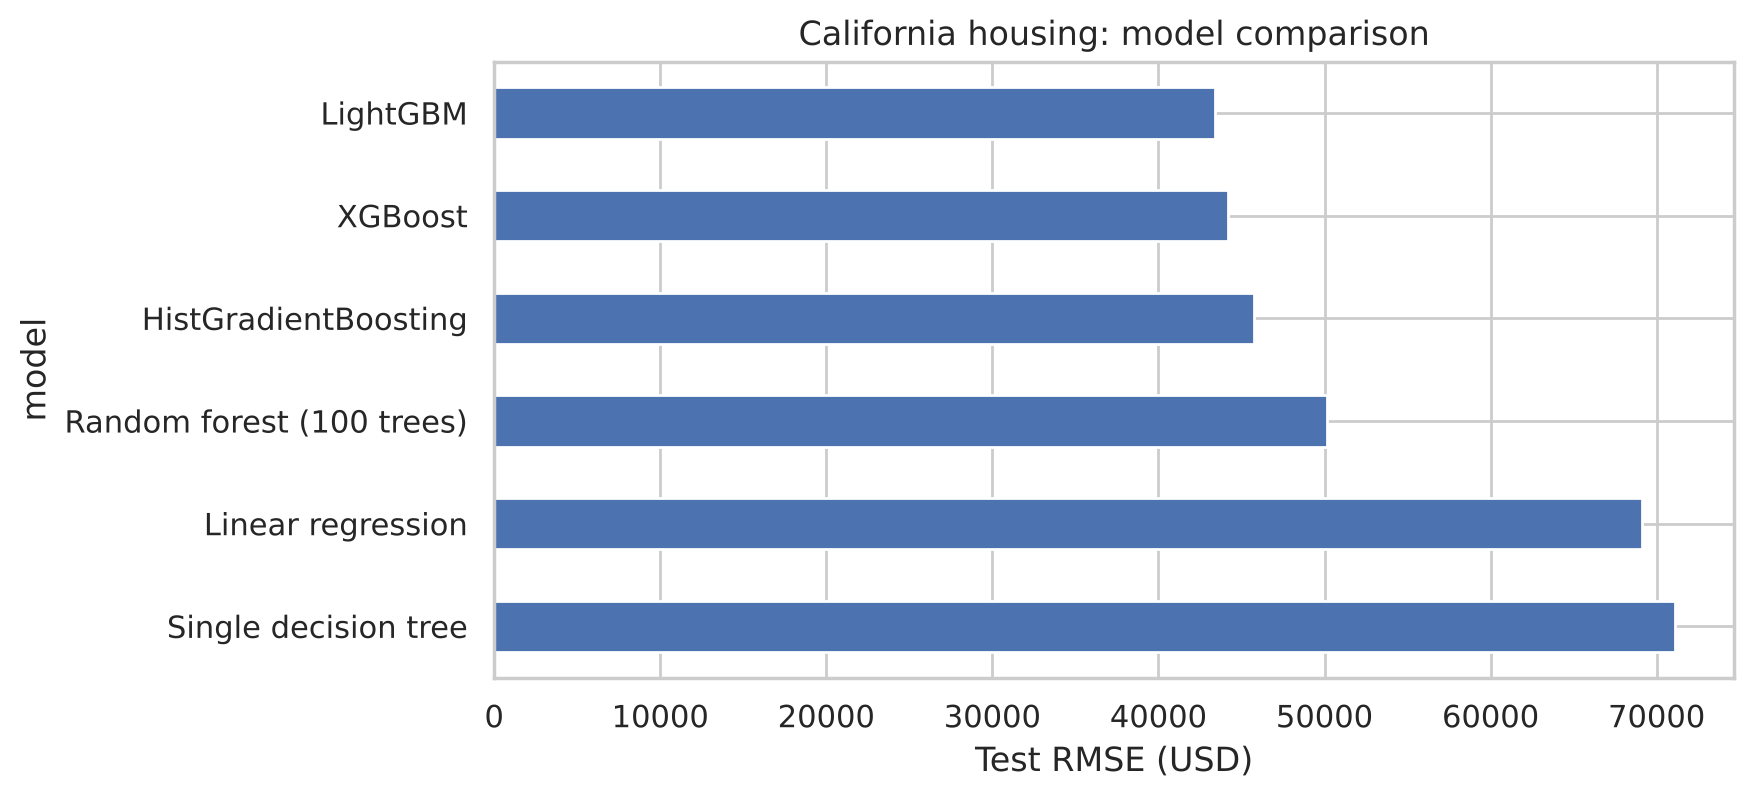

In [12]:
comparison.set_index("model")["RMSE"].sort_values(ascending=False).plot.barh(figsize=(8, 4))
plt.xlabel("Test RMSE (USD)")
plt.title("California housing: model comparison")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

کتابخانه‌های Boosting مدرن بهترین نتیجه را می‌دهند: RMSE حدود ۳۵٪ کمتر از رگرسیون خطی و $R^2$ حدود ۰٫۸۵. HistGradientBoosting با سرعت بسیار بالا، نتیجه‌ای نزدیک به XGBoost و LightGBM دارد. با تنظیم ابرپارامترها (جلسهٔ ۱۰) این عددها باز هم بهتر می‌شوند.

### ابرپارامترهای مهم Gradient Boosting

| ابرپارامتر | اثر |
|---|---|
| `n_estimators` / `max_iter` | تعداد درخت‌ها؛ با توقف زودهنگام تنظیم شود |
| `learning_rate` | کوچک‌تر یعنی تعمیم بهتر ولی درخت بیشتر |
| `max_depth` / `num_leaves` | پیچیدگی هر درخت |
| `subsample` | کسری از نمونه‌ها برای هر درخت؛ تصادفی‌سازی برای کاهش بیش‌برازش |
| `colsample_bytree` | کسری از ویژگی‌ها برای هر درخت |
| `reg_alpha`, `reg_lambda` | منظم‌سازی L1 و L2 روی وزن برگ‌ها (XGBoost و LightGBM) |

## ۷. Stacking

**Stacking** پیشرفته‌ترین روش ترکیب است: به‌جای رأی‌گیری ساده، یک **مدل نهایی (meta-learner)** یاد می‌گیرد که پیش‌بینی‌های مدل‌های پایه را چطور ترکیب کند. پیش‌بینی‌های ورودی مدل نهایی با اعتبارسنجی متقابل تولید می‌شوند تا نشت داده رخ ندهد. `StackingClassifier` و `StackingRegressor` در scikit-learn این کار را انجام می‌دهند. Stacking معمولاً بهبود کوچکی می‌دهد و بیشتر در مسابقات استفاده می‌شود.

## جمع‌بندی

- روش‌های گروهی با ترکیب مدل‌های متنوع، خطا را کم می‌کنند.
- **Bagging و Random Forest:** درخت‌های عمیق مستقل و موازی؛ کاهش واریانس؛ با تنظیمات پیش‌فرض هم قوی؛ امتیاز OOB رایگان.
- **Boosting:** درخت‌های کم‌عمق پشت سر هم که خطای قبلی را اصلاح می‌کنند؛ کاهش بایاس؛ نیاز به نرخ یادگیری و توقف زودهنگام.
- برای دادهٔ جدولی، **HistGradientBoosting، XGBoost و LightGBM** معمولاً بهترین نقطهٔ شروع‌اند.
- برای اهمیت ویژگی‌ها، Permutation Importance روی دادهٔ آزمون قابل اعتمادتر است.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## تمرین‌ها

هر تمرین را در سلول کد زیر آن حل کنید. پاسخ پیشنهادی در پوشهٔ `solutions` آمده است.

۱. در Random Forest بخش ۳، `max_features` را ۱، ۳ و `None` قرار دهید (`None` یعنی همان Bagging). کدام بهتر است؟

۲. شبیه‌سازی Gradient Boosting بخش ۵.۲ را با `learning_rate=0.3` و ۲۰ درخت تکرار کنید و منحنی نهایی را رسم کنید.

۳. در `HistGradientBoostingRegressor`، به‌جای `OrdinalEncoder` از پارامتر `categorical_features="from_dtype"` استفاده کنید (ستون را به نوع `category` تبدیل کنید). نتیجه تغییر می‌کند؟

۴. یک `StackingRegressor` با Random Forest، HistGradientBoosting و رگرسیون خطی بسازید و با بهترین مدل تکی مقایسه کنید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۱.** در Random Forest بخش ۳، `max_features` را ۱، ۳ و `None` قرار دهید (`None` یعنی همان Bagging). کدام بهتر است؟

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۲.** شبیه‌سازی Gradient Boosting بخش ۵.۲ را با `learning_rate=0.3` و ۲۰ درخت تکرار کنید و منحنی نهایی را رسم کنید.

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۳.** در `HistGradientBoostingRegressor`، به‌جای `OrdinalEncoder` از پارامتر `categorical_features="from_dtype"` استفاده کنید (ستون را به نوع `category` تبدیل کنید). نتیجه تغییر می‌کند؟

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۴.** یک `StackingRegressor` با Random Forest، HistGradientBoosting و رگرسیون خطی بسازید و با بهترین مدل تکی مقایسه کنید.

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید
